# Workforce Wage Patterns

How do hourly wages differ across occupation categories?

Data: [AER/CPS1985](https://vincentarelbundock.github.io/Rdatasets/doc/AER/CPS1985.html)

This notebook performs a descriptive analysis on a real historical dataset. Source limitations: Historical survey; reported means are unweighted unless survey weights are supplied.

In [1]:
from pathlib import Path
from analysis import run
result = run(Path.cwd())
result["manifest"]

Out[0]: 
{'project': 'Workforce Wage Patterns',
 'executed_utc': '2026-11-21T10:14:15.001363+00:00',
 'source': 'https://vincentarelbundock.github.io/Rdatasets/csv/AER/CPS1985.csv',
 'documentation': 'https://vincentarelbundock.github.io/Rdatasets/doc/AER/CPS1985.html',
 'sha256': '1b4bf681b94ecb82e534a0f97773c704205e13ccf13d273e439e44eaa9f5435c',
 'raw_rows': 534,
 'analysis_rows': 534,
 'excluded_rows': 0,
 'exact_duplicate_rows': 0,
 'duplicates_policy': 'Retained; duplicate values do not necessarily mean duplicate entities.',
 'python': '3.12.14',
 'pandas': '2.2.3',
 'numpy': '2.3.5',
 'matplotlib': '3.10.8'}


## Data quality
Missing required variables are excluded, not silently imputed. Repeated rows are preserved; review the source observation grain.

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("outputs/quality_audit.csv"))

,column,dtype,missing,missing_pct,distinct
0,rownames,int64,0,0.0,534
1,wage,float64,0,0.0,238
2,education,int64,0,0.0,17
3,experience,int64,0,0.0,52
4,age,int64,0,0.0,47
5,ethnicity,object,0,0.0,3
6,region,object,0,0.0,2
7,gender,object,0,0.0,2
8,occupation,object,0,0.0,6
9,sector,object,0,0.0,3


## SQL and analysis
Complete-case descriptive comparison of wage by occupation; show group counts, mean, minimum and maximum.

In [3]:
print(Path("analysis.sql").read_text())
display(result["table"].head(30))
print(result["finding"])

SELECT "occupation" AS segment, COUNT(*) AS rows_used, AVG("wage") AS metric, MIN("wage") AS minimum, MAX("wage") AS maximum FROM observations GROUP BY "occupation" ORDER BY "occupation";

The largest observed mean wage is 12.704 for management. This ranking is descriptive, not a recommendation.


,segment,rows_used,metric,minimum,maximum
0,management,55,12.704000,1.00,44.50
1,office,97,7.422577,3.00,15.03
2,sales,38,7.592632,3.35,19.98
3,services,83,6.537470,1.75,25.00
4,technical,105,11.947429,4.35,24.98
5,worker,156,8.426474,2.85,26.00


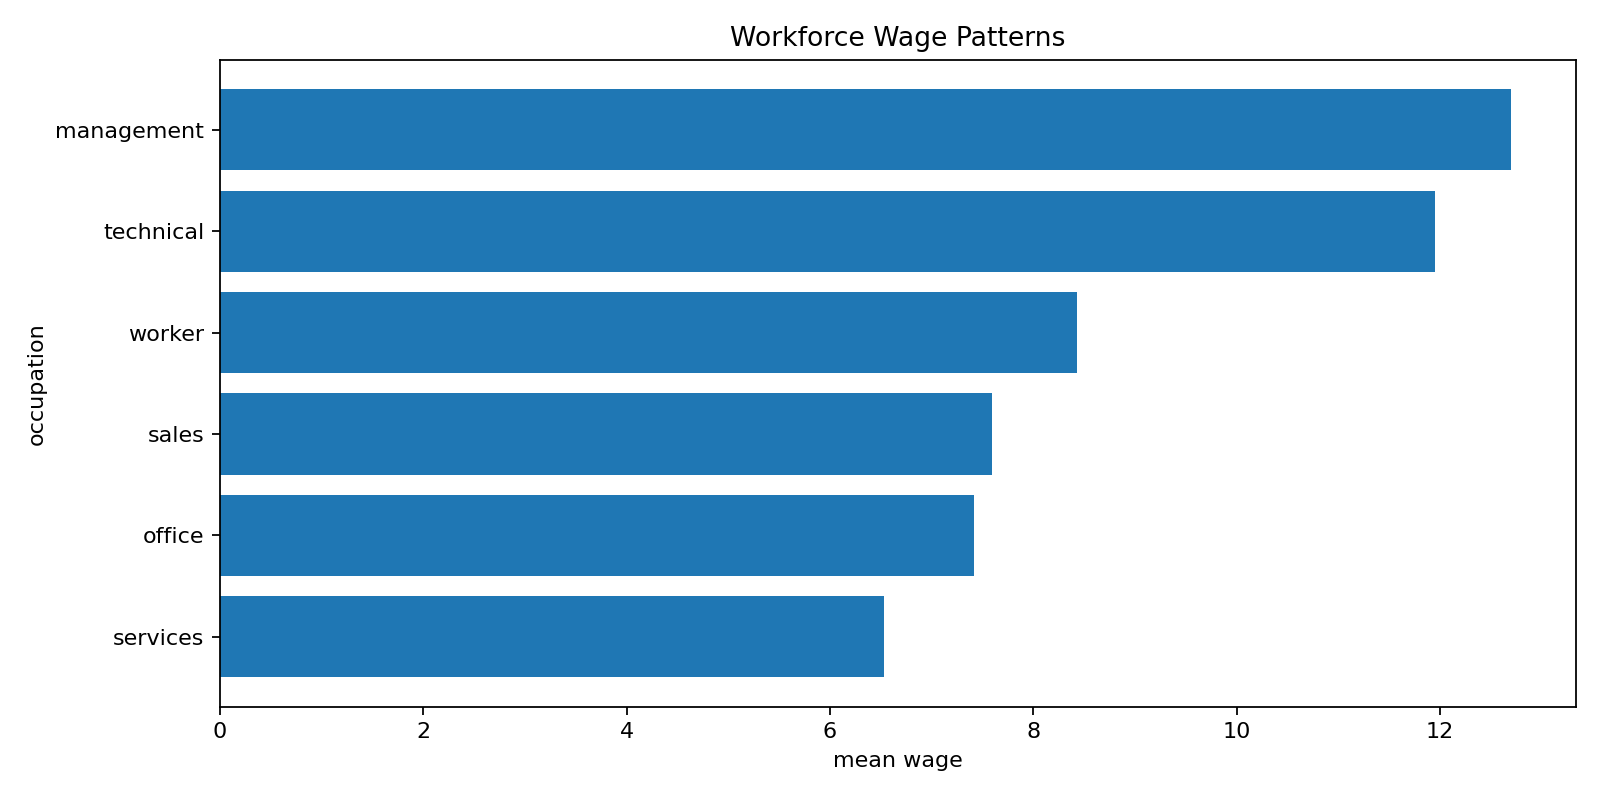

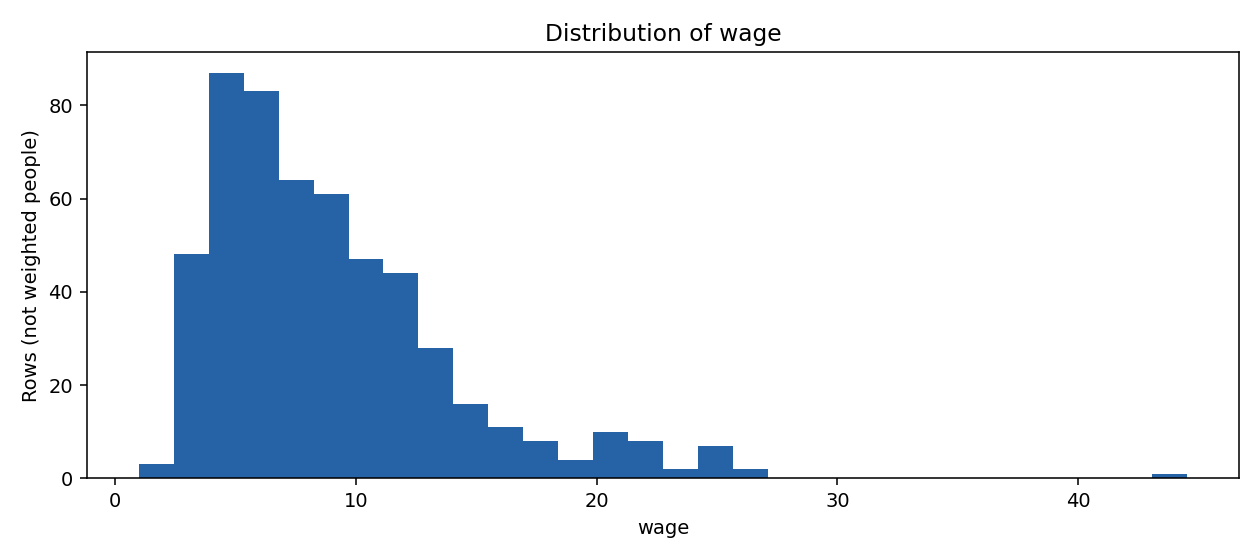

In [4]:
display(Image(filename="outputs/main_chart.png"))
display(Image(filename="outputs/distribution.png"))

## Interpretation
Historical survey; reported means are unweighted unless survey weights are supplied.

**Next action:** Review sample design and adjust for experience and education.

Read outputs/REPORT.md for executed findings. This project does not establish causation or a production decision rule.